# Experiências de comunicação com e sem SA

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

# Comunicação e PR-AUC — Softlabels

**Comparação emparelhada com/sem SA dentro de cada abordagem.** Mesmos IDs, cinco seeds (2031–2035), três rondas e dez épocas locais. 22 clientes, pesos de fit: 72,73% Icentia e 27,27% PhysioNet. Sem desistências nesta comparação. SA: soma única, 24 bits, limiar 12. FedAvg usa CNN1D comum; Soft Labels usa professores AE+CNN/MobileNetV2 e aluno CNN1D. A diferença entre abordagens inclui arquitetura/objetivo e custo de treino distintos; as épocas iguais não igualam FLOPs.

{'status': 'complete', 'validated_runs': 20, 'signature': '590f95d2e0ae0804092eeab9326543fffa70e3b18e6d11584e39f0b18bdacb98'}

**20/20 execuções concluídas e validadas.** Barras parciais só incluem execuções completas; `n` indica seeds disponíveis.

PR-AUC local: professor no próprio holdout nas Soft Labels; rede local após treino, antes da agregação, em FedAvg. PR-AUC global: o modelo global avaliado nos mesmos holdouts. Média ponderada dos AP individuais, não uma curva conjunta. O modelo FedAvg entregue ao cliente após agregação corresponde à barra global. Dev é secundário e está nas tabelas por cliente; test não é usado. AP indefinida num holdout com uma só classe é excluída, com cobertura explícita nas tabelas.

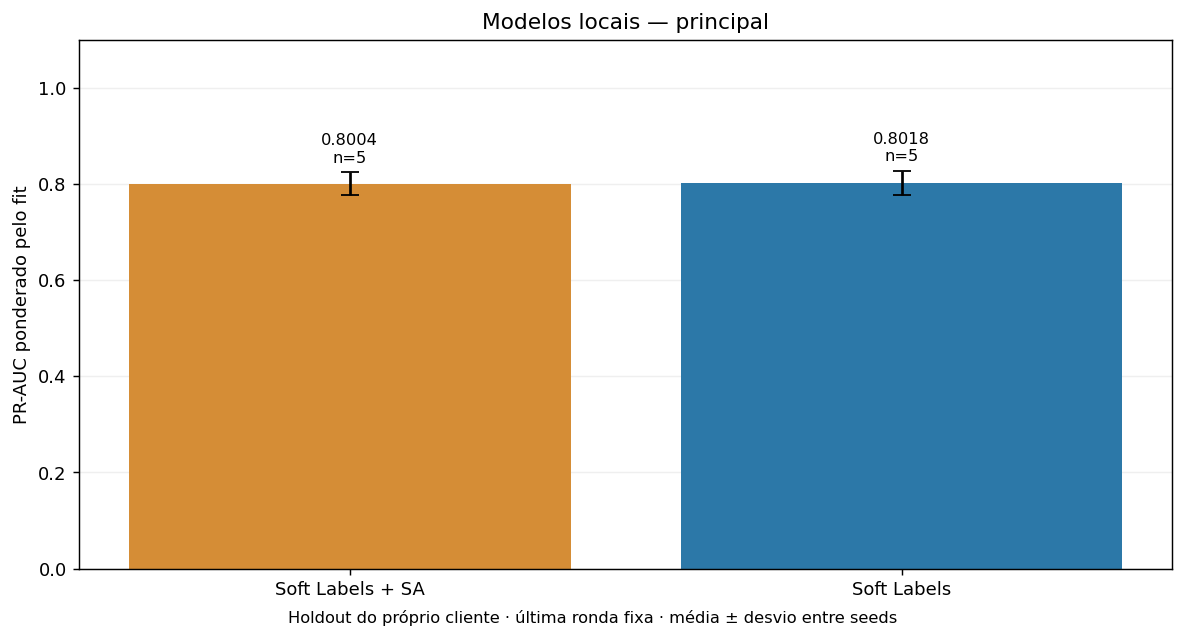

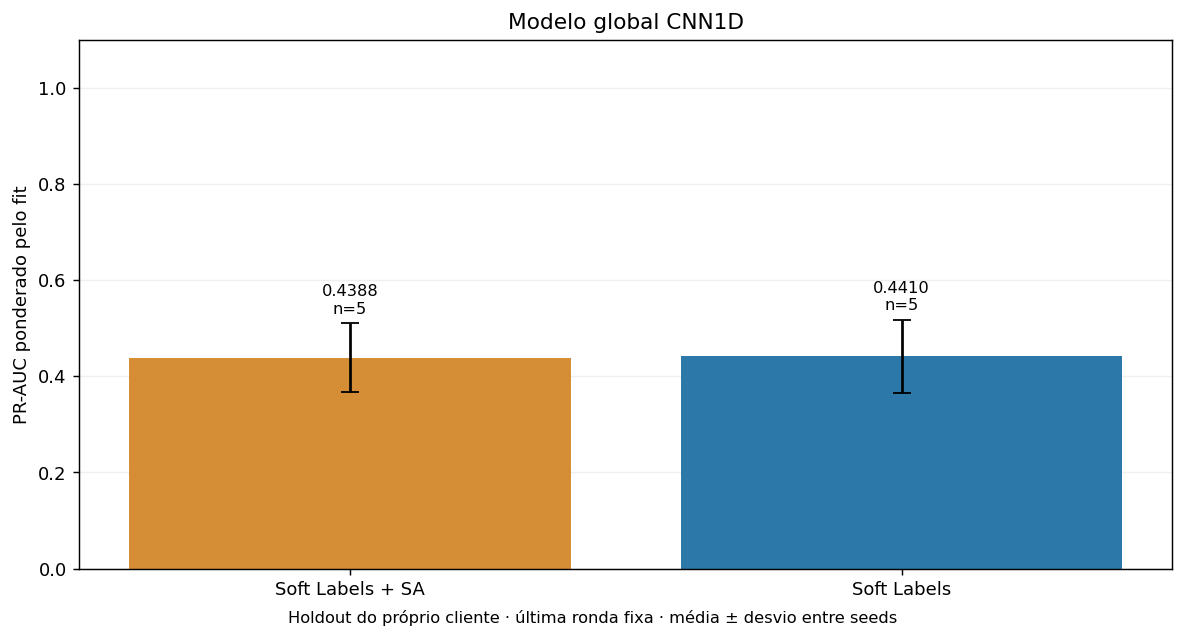

algorithm,condition,seed,role,pr_auc_ap,roc_auc,recall,far,f1,valid_ap_clients,total_clients,ap_fit_coverage
Softlabels,SA,2031,global,0.440535,0.511685,0.300699,0.305646,0.222558,22,22,1.0
Softlabels,SA,2031,local,0.800708,0.856585,0.630432,0.090920,0.643605,22,22,1.0
Softlabels,SA,2032,global,0.505314,0.564610,0.937063,0.915945,0.450422,22,22,1.0
Softlabels,SA,2032,local,0.777926,0.821223,0.724026,0.177432,0.699396,22,22,1.0
Softlabels,SA,2033,global,0.318601,0.324350,0.068619,0.185334,0.094192,22,22,1.0
Softlabels,SA,2033,local,0.839294,0.868800,0.741196,0.159684,0.709317,22,22,1.0
Softlabels,SA,2034,global,0.477979,0.568581,1.000000,0.985508,0.460739,22,22,1.0
Softlabels,SA,2034,local,0.785478,0.834052,0.600462,0.146650,0.605631,22,22,1.0
Softlabels,SA,2035,global,0.451439,0.530458,1.000000,0.997067,0.457817,22,22,1.0
Softlabels,SA,2035,local,0.798561,0.853729,0.708666,0.162575,0.678885,22,22,1.0


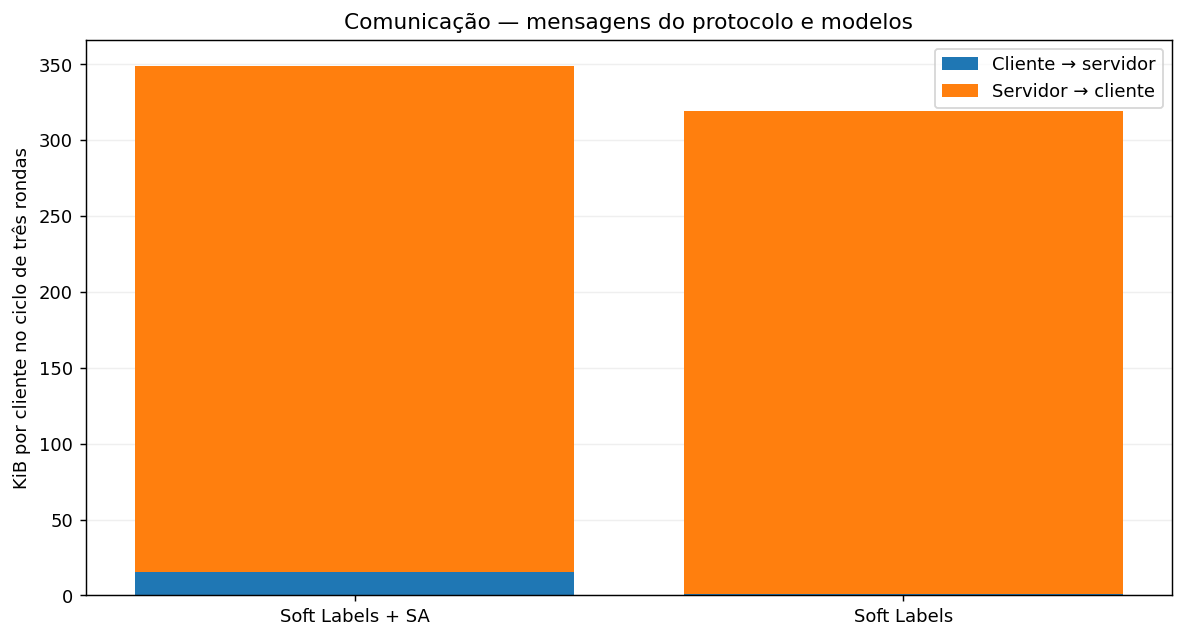

algorithm,condition,seed,upload_bytes,download_bytes,total_bytes,aggregation_seconds,local_compute_seconds
Softlabels,SA,2031,350064,7509920,7859984,6.005670,1666.745800
Softlabels,SA,2032,350064,7509920,7859984,4.020914,1164.760554
Softlabels,SA,2033,350064,7509920,7859984,4.009358,1157.875132
Softlabels,SA,2034,350064,7509920,7859984,4.932616,1454.197553
Softlabels,SA,2035,350064,7509920,7859984,5.405786,2259.877847
Softlabels,plain,2031,17160,7182560,7199720,0.000058,1622.775829
Softlabels,plain,2032,17160,7182560,7199720,0.000054,1592.655218
Softlabels,plain,2033,17160,7182560,7199720,0.000045,1243.701335
Softlabels,plain,2034,17160,7182560,7199720,0.000050,1185.214595
Softlabels,plain,2035,17160,7182560,7199720,0.000059,1870.979222


condition,algorithm,seed,role,SA,plain,SA_minus_plain
,Softlabels,2031,global,0.440535,0.452283,-0.011748
,Softlabels,2031,local,0.800708,0.788336,0.012372
,Softlabels,2032,global,0.505314,0.504633,0.000682
,Softlabels,2032,local,0.777926,0.788149,-0.010222
,Softlabels,2033,global,0.318601,0.309112,0.009489
,Softlabels,2033,local,0.839294,0.844688,-0.005394
,Softlabels,2034,global,0.477979,0.485029,-0.007050
,Softlabels,2034,local,0.785478,0.782420,0.003057
,Softlabels,2035,global,0.451439,0.453975,-0.002535
,Softlabels,2035,local,0.798561,0.805574,-0.007012


Comunicação: soma dos payloads de upload e download; inclui chaves, partilhas e desmascaramento da SA, distribuição inicial e três distribuições globais (uma após cada ronda). Contagem por mensagem lógica, sem cabeçalhos TCP/TLS nem retransmissões. Âncoras sintéticas geradas localmente; preparação inicial dos dados não contabilizada. Tempos medidos localmente, sem latência de rede. FedAvg: parâmetros com sinal codificados por transformação afim com limite público ±256, sem clipping silencioso; buffers inteiros são arredondados. Soft Labels: probabilidades ponderadas em [0,1]. Os 24 bits não representam o mesmo erro absoluto nos dois espaços. SA não oferece LDP nem esta simulação constitui uma validação de segurança para produção.

In [1]:
from support.sa_communication_report import render
render('Softlabels')

## Segurança — Soft Labels sem SA vs Soft Labels com SA

O objetivo da SA é limitar a exposição das contribuições individuais ao servidor, permitindo recuperar a soma ponderada. **Um PR-AUC semelhante não demonstra confidencialidade.** Esta secção separa as propriedades pretendidas, as verificações funcionais realizadas e as limitações não avaliadas.

Modelo de ameaça desta implementação: **servidor honesto mas curioso**, que segue o protocolo. A comparação usa a configuração A, os mesmos dados, cinco seeds, três rondas, dez épocas locais, 22 clientes e pesos de fit 72,73%/27,27%. SA: soma única de probabilidades ponderadas, 24 bits, limiar 12, novas chaves/máscaras em cada ronda, sem desistências nos treinos completos. A avaliação de desistências abaixo é isolada e sintética.

| Informação ou propriedade | Sem SA | Com SA |
|---|---|---|
| ECG privados enviados na mensagem de aprendizagem | Não | Não |
| Probabilidades individuais acessíveis em claro ao servidor | Sim | Não no fluxo previsto; os payloads recebidos estão mascarados |
| Agregado ponderado disponível | Sim | Sim, após desmascaramento |
| Identificadores, participação e contagens públicas de fit | Conhecidos | Continuam conhecidos |
| Modelo global disponível ao servidor | Sim | Sim |
| Garantia LDP / orçamento epsilon | Não | Não; SA não acrescenta uma garantia LDP |
| Proteção contra inferência a partir do agregado/modelo | Não demonstrada | Não demonstrada |

A coluna com SA descreve a visão pretendida do servidor do protocolo. A simulação corre num único processo, que possui os dados para executar clientes e avaliar os resultados. A separação entre clientes e servidor é lógica, não isolamento de processos ou dispositivos. Os artefactos privados de avaliação não são mensagens do treino. Os testes abaixo não constituem prova criptográfica nem certificação da implementação.

**Limitação da integração atual:** a função de simulação `aggregate(messages, ...)` recebe as contribuições em claro, calcula uma referência para medir o erro e só depois invoca a soma segura com clientes simulados. Portanto, estes treinos não demonstram uma ocultação end-to-end das contribuições ao processo agregador. Numa implantação real, cada cliente teria de preparar e mascarar a mensagem antes de a enviar; a referência em claro ficaria num avaliador de testes separado e de confiança.


### Utilidade e custo da proteção — treinos completos

metrica,sem_SA,com_SA,diferenca,unidade
PR-AUC local,0.801833,0.800394,-0.001440,AP; média de cinco seeds
PR-AUC global,0.441006,0.438774,-0.002232,AP; média de cinco seeds
Upload por cliente,0.761719,15.539062,14.777344,KiB/cliente/ciclo
Download por cliente,318.828125,333.359375,14.531250,KiB/cliente/ciclo
Comunicação total por cliente,319.589844,348.898438,29.308594,KiB/cliente/ciclo
Tempo de agregação acumulado,0.000053,4.874869,4.874815,s/ciclo; simulação local


condition,rondas,erro_medio,maior_erro
SA,15,8.827731e-08,3.132513e-07
plain,15,0.000000e+00,0.000000e+00


As diferenças de AP são com SA menos sem SA, nas mesmas cinco seeds. A condição SA inclui quantização a 24 bits: o efeito observado no treino não deve ser atribuído só à criptografia. Nas 15 rondas de treino com SA, foi verificado que a soma inteira segura coincide com a soma dos inteiros quantizados. O erro em probabilidades é medido separadamente contra a referência sem quantização. Bytes são payloads lógicos, sem TCP/TLS; o tempo inclui preparação e geração de chaves, sem rede real. RAM e energia no wearable não foram medidas.

### Verificações funcionais isoladas — dados artificiais

Usam-se 22 vetores artificiais de 64 probabilidades, pesos 1/22, 24 bits e limiar 12. Não são novos treinos, ataques aos ECG ou resultados de privacidade sobre os pacientes.

cenario,mensagens,respostas,resultado,esperado
Sem desistências,22,22,Concluiu; soma inteira exata,True
Quatro desistem antes de enviar,18,18,Concluiu; soma inteira exata,True
Dezoito enviam; doze desmascaram,18,12,Concluiu; soma inteira exata,True
Dezoito enviam; só onze desmascaram,18,11,Recusou: respostas abaixo de t,True


... (2 outputs left out)

### Integridade: proteção limitada observada

teste,resultado
Alteração de uma partilha cifrada,Rejeitada pelo HMAC
Alteração de uma coordenada do vetor mascarado,Aceite pela API; agregado alterado


**Limitação verificada:** o HMAC rejeita alterações nas partilhas cifradas, mas esta API não verifica a autenticidade dos vetores de contribuição mascarados. Alterar uma coordenada foi aceite e alterou o agregado. O teste é ativo e está fora da hipótese de execução honesta; não invalida a soma correta nos testes sem manipulação, mas impede afirmar proteção geral contra mensagens adulteradas. Não foi simulado um transporte autenticado.

### Comparação visual sob ameaças maliciosas

A imagem distingue exposição verificada, proteção limitada, proteção funcional observada e ataques não avaliados. Não se atribuem níveis numéricos de segurança a partir de testes de correção. A primeira linha é uma referência com servidor cumpridor; as restantes exploram ameaças e limites do protótipo.

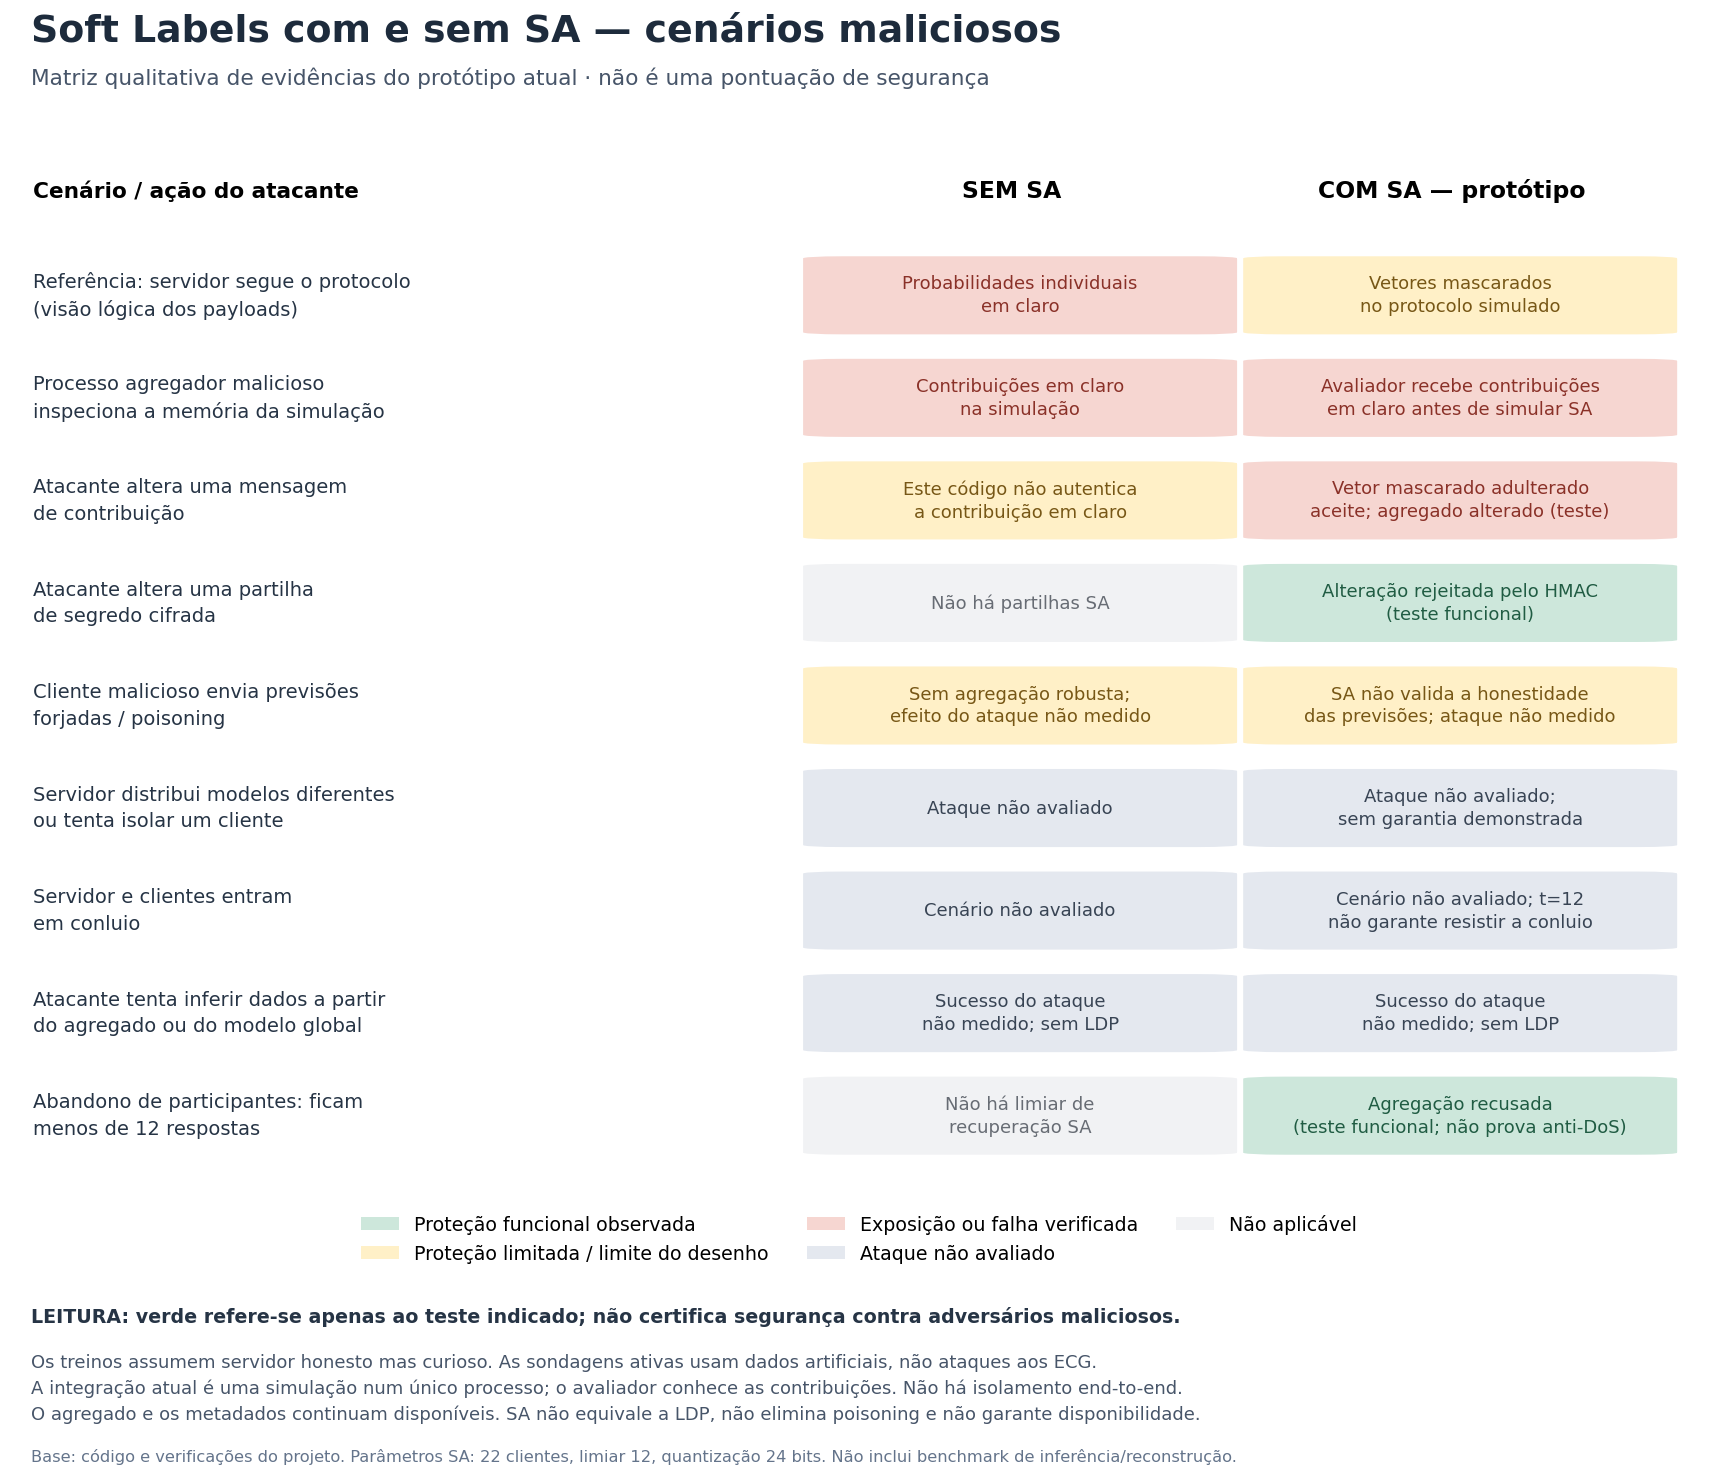

### Conclusão de segurança

Comparativamente à transmissão em claro, **SA limita a exposição das probabilidades individuais no fluxo previsto**, mantendo disponível o agregado e acrescentando custo de comunicação/cálculo. A correção da soma e a recusa abaixo do limiar foram verificadas funcionalmente; não demonstram por si só uma garantia criptográfica da implementação. **Não foram medidos ataques de reconstrução, inferência de pertença/propriedades, conluio ou isolamento de clientes.** O limiar 12 é de recuperação; não significa automaticamente tolerar 11 clientes em conluio. O agregado, a participação e o modelo global continuam disponíveis e podem revelar informação; SA não oferece LDP nem elimina poisoning. A integridade dos vetores e cenários com servidor malicioso requerem mecanismos e avaliação adicionais.

Referências: [Bonawitz et al., 2017 — Secure Aggregation](https://research.google/pubs/practical-secure-aggregation-for-privacy-preserving-machine-learning/); [Pasquini et al. — limites perante servidor malicioso](https://arxiv.org/abs/2111.07380).

In [2]:
from support.sa_softlabels_security import render
render()